# Phase 4 — Locked OASIS-3 External Validation

This notebook displays the completed, saved Phase 4 results. The analysis used
the repaired immutable lock at `models/phase3/phase4_lock_v2`.

Execution order was enforced: lock verification → outcome-hidden feature
construction → frozen predictions → independent prediction verification →
outcome merge → untouched validation → endpoint sensitivity → cross-fitted
recalibration → independent final QC.

The notebook does not refit or retune models. It reads the machine-readable
saved outputs so every result remains traceable to the frozen analysis.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "results" / "csvs" / "phase4").exists():
    ROOT = ROOT.parent

TABLES = ROOT / "results" / "csvs" / "phase4"
PLOTS = ROOT / "results" / "plots" / "phase4"
REPORTS = ROOT / "reports" / "phase4"
LOCK = ROOT / "models" / "phase3" / "phase4_lock_v2"

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 180)

metadata = json.loads((TABLES / "phase4_run_metadata.json").read_text())
print(f"Project root: {ROOT}")
print(f"Frozen lock: {metadata['lock_path']}")
print(f"Lock version: {metadata['lock_package_version_id']}")
print(f"Phase 4 complete: {metadata['phase4_complete']}")
print(f"Phase 5 started: {metadata['phase5_started']}")
print(f"Final decision: {metadata['decision']}")

Project root: /media/faizaan/4TB/1_DATA_PROJECTS/2026/July clinical data adni and oasis and aibl
Frozen lock: models/phase3/phase4_lock_v2
Lock version: phase3-adni-lockrepair-v2-294971626abc
Phase 4 complete: True
Phase 5 started: False
Final decision: GO TO PHASE 5 WITH RESTRICTIONS


## 1. Lock verification and execution-order gates

No OASIS participant-level outcome was opened until all outcome-hidden
predictions had been frozen and independently regenerated.

In [2]:
stage_a = pd.read_csv(TABLES / "phase4_stage_a_qc_results.csv")
final_qc = pd.read_csv(TABLES / "phase4_qc_results.csv")
display(stage_a)
display(final_qc[["check_id", "section", "check", "status", "details"]])
assert stage_a["status"].eq("PASS").all()
assert final_qc["status"].eq("PASS").all()
print(f"Stage A: {len(stage_a)}/{len(stage_a)} PASS")
print(f"Independent final QC: {len(final_qc)}/{len(final_qc)} PASS")

,check_id,stage,description,severity,status,details
0,A01,A,independent repaired-lock QC is current and fu...,critical,PASS,checks=18; failures=0
1,A02,A,external manifest authenticates the frozen ind...,critical,PASS,index=6fdae9393bb478f78d6c534416516023a5e5dfe2...
2,A03,A,all phase4_lock_v2 checksums and byte sizes pass,critical,PASS,55/55 PASS
3,A04,A,all Phase 4 required model/horizon bundles are...,critical,PASS,"present=[('B1', 12), ('B1', 24), ('B1', 36), (..."
4,A05,A,"schemas, preprocessing, coefficients, penaltie...",critical,PASS,bundles=14; failures=0
5,A06,A,inference compatibility and original-copy equi...,critical,PASS,new_fixtures=6; copy_comparisons=8
6,A07,A,lock development cohort is ADNI and external o...,critical,PASS,all 14 bundles external_outcomes_accessed=False
7,A08,A,Stage A accessed no OASIS participant-level fe...,critical,PASS,Stage A read only the repaired lock and its in...


,check_id,section,check,status,details
0,Q01,lock,independent repaired-lock QC remains fully pas...,PASS,checks=18; failures=0
1,Q02,lock,external lock descriptor authenticates index a...,PASS,index=True; checksum_manifest=True
2,Q03,lock,all repaired-lock files pass hashes/sizes and ...,PASS,hashes=55/55; extras=[]; missing=[]
3,Q04,lock,original phase4_lock remains unchanged,PASS,verified=16/16
4,Q05,lock,all required model/horizon bundles and frozen ...,PASS,bundles=14; missing=[]; component_failures=0
5,Q06,lock,D3 is strictly pre-landmark and all dynamic fo...,PASS,d3=2/2; grouping=10/10
6,Q07,prediction_freeze,prediction manifest and all 28 outcome-hidden ...,PASS,manifest_hash=True; files=28/28
7,Q08,prediction_freeze,all frozen prediction files remain outcome-free,PASS,outcome_free=28/28
8,Q09,prediction_freeze,independent prediction regeneration passes to ...,PASS,checks=4; failures=0; maximum_difference=2.22e-16
9,Q10,prediction_freeze,expected OASIS populations and probability coh...,PASS,population=14/14; coherence=14/14


Stage A: 8/8 PASS
Independent final QC: 28/28 PASS


In [3]:
access = pd.read_csv(TABLES / "phase4_access_audit.csv")
display(access[[
    "sequence", "timestamp_utc", "stage", "action",
    "oasis_record_level_features_accessed",
    "oasis_record_level_outcomes_accessed",
    "outcome_hidden_predictions_created",
]])

freeze = json.loads((TABLES / "prediction_freeze_metadata.json").read_text())
print("Prediction freeze:", freeze["freeze_timestamp_utc"])
print("Independent prediction QC:", freeze["independent_prediction_qc_completed_at_utc"])
print("First outcome access:", freeze["outcomes_first_accessed_at_utc"])

,sequence,timestamp_utc,stage,action,oasis_record_level_features_accessed,oasis_record_level_outcomes_accessed,outcome_hidden_predictions_created
0,1,2026-07-29T14:01:51.037485+00:00,A,re-run complete phase4_lock_v2 verification,False,False,False
1,2,2026-07-29T14:01:51.037485+00:00,B_PREFLIGHT,predictor-only population/schema preflight aft...,True,False,False
2,3,2026-07-29T14:01:51.839665+00:00,B,read outcome-hidden B1 12m predictors and free...,True,False,True
3,4,2026-07-29T14:01:52.121925+00:00,B,read outcome-hidden B1 24m predictors and free...,True,False,True
4,5,2026-07-29T14:01:52.411372+00:00,B,read outcome-hidden B1 36m predictors and free...,True,False,True
5,6,2026-07-29T14:01:52.710340+00:00,B,read outcome-hidden B1 60m predictors and free...,True,False,True
6,7,2026-07-29T14:01:52.973725+00:00,B,read outcome-hidden B3 12m predictors and free...,True,False,True
7,8,2026-07-29T14:01:53.254707+00:00,B,read outcome-hidden B3 36m predictors and free...,True,False,True
8,9,2026-07-29T14:01:53.702547+00:00,B,read outcome-hidden D0 12m predictors and free...,True,False,True
9,10,2026-07-29T14:01:54.187669+00:00,B,read outcome-hidden D0 36m predictors and free...,True,False,True


Prediction freeze: 2026-07-29T14:01:56.722145+00:00
Independent prediction QC: 2026-07-29T14:03:59.826609+00:00
First outcome access: 2026-07-29T14:14:22.793677+00:00


In [4]:
display(Image(filename=str(PLOTS / "phase4_stage_gate_workflow.png"), width=1200))

## 2. Frozen models, external populations, and deterministic predictions

B1 is the baseline clinical model; D0 is the dynamic comparator; D1 is the
selected dynamic model; B3 removes APOE; D3 restricts MMSE to strictly
pre-landmark observations.

In [5]:
inventory = pd.read_csv(LOCK / "model_inventory.csv")
display(inventory[[
    "model_id", "family", "horizon_months", "model_origin",
    "training_rows", "training_participants", "improvement_alpha",
    "progression_alpha", "external_outcomes_accessed", "sha256",
]].sort_values(["model_id", "horizon_months"]))

population = pd.read_csv(TABLES / "outcome_hidden_population_verification.csv")
display(population)
assert population["status"].eq("PASS").all()

,model_id,family,horizon_months,model_origin,training_rows,training_participants,improvement_alpha,progression_alpha,external_outcomes_accessed,sha256
0,B1,baseline,12,verified_copy_from_original_lock,2447,2447,10.0,10.0,False,b408adbf1644174870ad96a4df3df633e9a3f53c6b2a5a...
1,B1,baseline,24,verified_copy_from_original_lock,2447,2447,10.0,10.0,False,5cd4e5e45316f20bee3a3c0d88b11d9bf11b745f20bc46...
2,B1,baseline,36,verified_copy_from_original_lock,2447,2447,10.0,10.0,False,52baf11e3cd593770ce25145a08fff317264aa0f95e972...
3,B1,baseline,60,verified_copy_from_original_lock,2447,2447,10.0,100.0,False,e3d9f777e6cdaacc45e7ae91f1273de08f97e6879cd35f...
4,B3,baseline,12,adni_only_outcome_blind_lock_repair,2447,2447,10.0,10.0,False,36fa8fe7d5047909bcef6ca3ded4b7f5621ce8de395c97...
5,B3,baseline,36,adni_only_outcome_blind_lock_repair,2447,2447,10.0,10.0,False,6a5fdaad7f1554bc588e22e7c8042fa4ef099e740307f4...
6,D0,dynamic,12,adni_only_outcome_blind_lock_repair,4517,1412,10.0,100.0,False,df4ce2b2ef7a32369c81b582eb81d8426aa6d807861013...
7,D0,dynamic,36,adni_only_outcome_blind_lock_repair,4517,1412,100.0,100.0,False,5d13f2f90552eadb03d947a13894ae6c583cbdf0cb6034...
8,D1,dynamic,12,verified_copy_from_original_lock,4517,1412,100.0,100.0,False,f2e05fbfe91fdfe31ee46dcd674c09ffa46be7262ab299...
9,D1,dynamic,24,verified_copy_from_original_lock,4517,1412,100.0,100.0,False,14cd2e62ca7ee94e0cdb749d1ecab981c2d14e643428b2...


,model_id,family,horizon_months,expected_rows,observed_rows,expected_participants,observed_participants,d1_observed_mmse_eligibility_applied,status
0,B1,baseline,12,491,491,491,491,False,PASS
1,B1,baseline,24,491,491,491,491,False,PASS
2,B1,baseline,36,491,491,491,491,False,PASS
3,B1,baseline,60,491,491,491,491,False,PASS
4,B3,baseline,12,491,491,491,491,False,PASS
5,B3,baseline,36,491,491,491,491,False,PASS
6,D0,dynamic,12,858,858,437,437,False,PASS
7,D0,dynamic,36,858,858,437,437,False,PASS
8,D1,dynamic,12,845,845,437,437,True,PASS
9,D1,dynamic,24,845,845,437,437,True,PASS


In [6]:
prediction_manifest = pd.read_csv(TABLES / "outcome_hidden_prediction_manifest.csv")
prediction_qc = pd.read_csv(TABLES / "independent_prediction_regeneration.csv")
coherence = pd.read_csv(TABLES / "outcome_hidden_probability_coherence.csv")

display(prediction_manifest[[
    "model_id", "horizon_months", "file_role", "rows", "participants",
    "outcome_columns_present", "status", "sha256",
]])
display(prediction_qc[[
    "model_id", "horizon_months", "rows", "participants",
    "maximum_point_prediction_difference",
    "maximum_curve_prediction_difference", "status",
]])
display(coherence)
print("Maximum independent regeneration difference:",
      max(prediction_qc["maximum_point_prediction_difference"].max(),
          prediction_qc["maximum_curve_prediction_difference"].max()))

,model_id,horizon_months,file_role,rows,participants,outcome_columns_present,status,sha256
0,B1,12,point_prediction,491,491,False,PASS,3d307ee285896530d2fc90611d0efd2d1d1aafc2341f46...
1,B1,12,time_grid_prediction,9820,491,False,PASS,be26dcdcdd9df9cac186a7306911a05a4298d680e22061...
2,B1,24,point_prediction,491,491,False,PASS,26957d59dba0323d0414b8c54cd7ff5ea46e280945a4cc...
3,B1,24,time_grid_prediction,9820,491,False,PASS,eb1970045b456c25c4b26db26bdce03854f35dd6f1dff0...
4,B1,36,point_prediction,491,491,False,PASS,0b3f3394c7f83c638259976606196567dfebe854e57608...
5,B1,36,time_grid_prediction,9820,491,False,PASS,5c6140351ce6be48965165345a43b40eeac47f3060d8eb...
6,B1,60,point_prediction,491,491,False,PASS,b21b7e9daaec4950df37e66030a80384d900dfc3694c6f...
7,B1,60,time_grid_prediction,9820,491,False,PASS,0794324b857cd0b7a8693d8d8ef8f68d45cd6afd83aa23...
8,B3,12,point_prediction,491,491,False,PASS,391f1bc799da3e41027f10e5c87228ccb437d03bc240c8...
9,B3,12,time_grid_prediction,9820,491,False,PASS,cf8d22d9e7462d800c7eb234de4eb93669f65c0a4c0b26...


,model_id,horizon_months,rows,participants,maximum_point_prediction_difference,maximum_curve_prediction_difference,status
0,B1,12,491,491,1.110223e-16,1.110223e-16,PASS
1,B1,24,491,491,1.110223e-16,1.110223e-16,PASS
2,B1,36,491,491,1.110223e-16,1.110223e-16,PASS
3,B1,60,491,491,1.110223e-16,1.110223e-16,PASS
4,B3,12,491,491,1.110223e-16,1.110223e-16,PASS
5,B3,36,491,491,1.110223e-16,1.110223e-16,PASS
6,D0,12,858,437,1.110223e-16,2.220446e-16,PASS
7,D0,36,858,437,1.110223e-16,1.110223e-16,PASS
8,D1,12,845,437,1.110223e-16,2.220446e-16,PASS
9,D1,24,845,437,1.110223e-16,2.220446e-16,PASS


,model_id,horizon_months,rows,minimum_probability,maximum_probability,maximum_absolute_sum_error,maximum_repeat_difference,curve_horizon_max_difference,status
0,B1,12,491,1.612937e-03,0.950999,2.220446e-16,0.0,0.0,PASS
1,B1,24,491,2.298301e-03,0.987825,2.220446e-16,0.0,0.0,PASS
2,B1,36,491,1.239113e-03,0.996318,2.220446e-16,0.0,0.0,PASS
3,B1,60,491,6.937832e-04,0.995016,2.220446e-16,0.0,0.0,PASS
4,B3,12,491,2.366037e-03,0.940376,2.220446e-16,0.0,0.0,PASS
5,B3,36,491,4.269574e-03,0.988996,2.220446e-16,0.0,0.0,PASS
6,D0,12,858,2.707794e-03,0.965721,2.220446e-16,0.0,0.0,PASS
7,D0,36,858,9.521050e-03,0.976590,2.220446e-16,0.0,0.0,PASS
8,D1,12,845,2.017654e-03,0.962194,2.220446e-16,0.0,0.0,PASS
9,D1,24,845,1.115068e-03,0.991071,2.220446e-16,0.0,0.0,PASS


Maximum independent regeneration difference: 2.220446049250313e-16


## 3. Primary untouched OASIS-3 results

The provisional primary endpoint is OASIS `CDRTOT`, treated as a de facto
global CDR. B1 12-month progression has only 18 events, so its estimate is
explicitly low precision.

In [7]:
events = pd.read_csv(TABLES / "baseline_event_count_verification.csv")
display(events)
assert events["status"].eq("PASS").all()

metrics = pd.read_csv(TABLES / "untouched_external_metrics.csv")
primary = metrics[
    metrics["model_id"].isin(["B1", "D0", "D1"])
    & metrics["horizon_months"].isin([12, 36])
].copy()
primary_columns = [
    "model_id", "horizon_months", "rows", "participants",
    "improvement_events", "progression_events",
    "auc_improvement", "auc_progression",
    "c_index_improvement", "c_index_progression",
    "brier_improvement", "brier_progression", "multistate_brier",
    "calibration_intercept_improvement", "calibration_slope_improvement",
    "observed_expected_improvement",
    "calibration_intercept_progression", "calibration_slope_progression",
    "observed_expected_progression",
]
display(primary[primary_columns].sort_values(["model_id", "horizon_months"]))

,horizon_months,expected_improvement,observed_improvement,expected_progression,observed_progression,status
0,12,45,45,18,18,PASS
1,24,143,143,58,58,PASS
2,36,170,170,101,101,PASS
3,60,187,187,150,150,PASS


,model_id,horizon_months,rows,participants,improvement_events,progression_events,auc_improvement,auc_progression,c_index_improvement,c_index_progression,brier_improvement,brier_progression,multistate_brier,calibration_intercept_improvement,calibration_slope_improvement,observed_expected_improvement,calibration_intercept_progression,calibration_slope_progression,observed_expected_progression
0,B1,12,491,491,45,18,0.695569,0.686107,0.677881,0.678121,0.093572,0.040970,0.263377,0.839809,1.418170,2.179343,-0.457370,0.655787,0.648185
2,B1,36,491,491,170,101,0.719800,0.719233,0.646754,0.647635,0.265600,0.172080,0.730509,1.131970,1.067938,2.244852,0.021282,0.671430,1.016128
6,D0,12,858,437,66,52,0.678926,0.650266,0.664621,0.644615,0.072148,0.057029,0.251117,0.773484,0.991375,2.076150,-0.236670,0.851765,0.802234
7,D0,36,858,437,243,265,0.724353,0.702135,0.668997,0.630655,0.223944,0.207503,0.720751,1.048566,1.617411,2.291737,0.178960,0.747241,1.129711
8,D1,12,845,437,66,49,0.680000,0.721221,0.667423,0.710593,0.073471,0.052534,0.245419,0.811980,1.697333,2.153523,-0.243612,1.085480,0.796474
10,D1,36,845,437,243,259,0.747207,0.729300,0.688435,0.655878,0.221384,0.197699,0.707110,1.046145,1.643548,2.282595,0.194244,0.832601,1.142928


In [8]:
ci = pd.read_csv(TABLES / "participant_bootstrap_confidence_intervals.csv")
auc_ci = ci[ci["metric"].isin([
    "auc_improvement", "auc_progression",
    "c_index_improvement", "c_index_progression",
    "multistate_brier", "observed_expected_improvement",
    "observed_expected_progression",
])].copy()
display(auc_ci.sort_values(["model_id", "horizon_months", "metric"]))
print("Bootstrap unit:", auc_ci["bootstrap_unit"].unique().tolist())
print("Replicates per estimate:", auc_ci["bootstrap_replicates"].unique().tolist())

,model_id,family,horizon_months,metric,bootstrap_replicates,valid_replicates,bootstrap_median,ci_low,ci_high,bootstrap_unit
0,B1,baseline,12,auc_improvement,1000,1000,0.696175,0.617840,0.769822,participant
1,B1,baseline,12,auc_progression,1000,1000,0.690230,0.544234,0.797847,participant
4,B1,baseline,12,multistate_brier,1000,1000,0.265014,0.213242,0.321526,participant
7,B1,baseline,12,observed_expected_improvement,1000,1000,2.182639,1.622051,2.824944,participant
10,B1,baseline,12,observed_expected_progression,1000,1000,0.644149,0.378517,0.948975,participant
15,B1,baseline,36,auc_improvement,1000,1000,0.719164,0.669831,0.769287,participant
16,B1,baseline,36,auc_progression,1000,1000,0.722150,0.660265,0.777479,participant
19,B1,baseline,36,multistate_brier,1000,1000,0.730086,0.688983,0.771275,participant
22,B1,baseline,36,observed_expected_improvement,1000,1000,2.244344,1.985119,2.494940,participant
25,B1,baseline,36,observed_expected_progression,1000,1000,1.021639,0.856803,1.203954,participant


Bootstrap unit: ['participant']
Replicates per estimate: [1000]


In [9]:
integrated = pd.read_csv(TABLES / "untouched_integrated_brier_scores.csv")
remaining = primary[[
    "model_id", "horizon_months",
    "calibration_intercept_remaining", "calibration_slope_remaining",
    "observed_expected_remaining", "observed_rate_remaining",
    "expected_rate_remaining",
]]
display(integrated)
display(remaining)

,endpoint,model_id,family,horizon_months,integrated_brier_improvement,integrated_brier_progression,integrated_brier_remaining,integrated_multistate_brier
0,CDRTOT_de_facto_global,B1,baseline,12,0.006117,0.005503,0.011982,0.023602
1,CDRTOT_de_facto_global,B1,baseline,24,0.111817,0.048082,0.137373,0.297272
2,CDRTOT_de_facto_global,B1,baseline,36,0.160956,0.084571,0.190390,0.435917
3,CDRTOT_de_facto_global,B1,baseline,60,0.200178,0.126203,0.199521,0.525902
4,CDRTOT_de_facto_global,B3,baseline,12,0.006113,0.005467,0.011965,0.023546
5,CDRTOT_de_facto_global,B3,baseline,36,0.162609,0.084034,0.188642,0.435284
6,CDRTOT_de_facto_global,D0,dynamic,12,0.005028,0.004807,0.009978,0.019814
7,CDRTOT_de_facto_global,D0,dynamic,36,0.129607,0.110501,0.186670,0.426779
8,CDRTOT_de_facto_global,D1,dynamic,12,0.005068,0.004555,0.009810,0.019433
9,CDRTOT_de_facto_global,D1,dynamic,24,0.086231,0.063252,0.128935,0.278417


,model_id,horizon_months,calibration_intercept_remaining,calibration_slope_remaining,observed_expected_remaining,observed_rate_remaining,expected_rate_remaining
0,B1,12,-0.301856,0.101032,0.962140,0.854694,0.888326
2,B1,36,-0.944629,0.121686,0.597899,0.342086,0.572147
6,D0,12,-0.228696,0.063306,0.971443,0.860307,0.885597
7,D0,36,-0.856176,0.078505,0.631160,0.358781,0.568446
8,D1,12,-0.252190,0.348823,0.969332,0.862418,0.889703
10,D1,36,-0.870466,0.217478,0.628709,0.361213,0.574531


In [10]:
display(Image(filename=str(PLOTS / "untouched_oasis_calibration_panels.png"), width=1050))

## 4. D1 value over D0 on matched landmarks

All D1-versus-D0 estimates use the same 845 landmark rows from 437
participants, with paired participant-level bootstrap confidence intervals.

In [11]:
comparisons = pd.read_csv(TABLES / "untouched_model_comparisons.csv")
d1d0 = comparisons[comparisons["comparison"].eq("D1_vs_D0_matched_rows")]
paired_ci = pd.read_csv(TABLES / "d1_vs_d0_paired_bootstrap_ci.csv")
display(d1d0)
display(paired_ci)

,comparison,horizon_months,common_rows,common_participants,left_model,right_model,metric,left_estimate,right_estimate,right_minus_left
0,D1_vs_D0_matched_rows,12,845,437,D0,D1,auc_improvement,0.677301,0.680000,0.002699
1,D1_vs_D0_matched_rows,12,845,437,D0,D1,auc_progression,0.650518,0.721221,0.070703
2,D1_vs_D0_matched_rows,12,845,437,D0,D1,brier_improvement,0.072908,0.073471,0.000563
3,D1_vs_D0_matched_rows,12,845,437,D0,D1,brier_progression,0.054589,0.052534,-0.002055
4,D1_vs_D0_matched_rows,12,845,437,D0,D1,multistate_brier,0.247766,0.245419,-0.002346
5,D1_vs_D0_matched_rows,12,845,437,D0,D1,calibration_intercept_improvement,0.781293,0.811980,0.030686
6,D1_vs_D0_matched_rows,12,845,437,D0,D1,calibration_slope_improvement,0.981961,1.697333,0.715372
7,D1_vs_D0_matched_rows,12,845,437,D0,D1,observed_expected_improvement,2.090828,2.153523,0.062695
8,D1_vs_D0_matched_rows,12,845,437,D0,D1,calibration_intercept_progression,-0.286518,-0.243612,0.042905
9,D1_vs_D0_matched_rows,12,845,437,D0,D1,calibration_slope_progression,0.861684,1.085480,0.223796


,comparison,horizon_months,metric,bootstrap_replicates,bootstrap_median_difference,ci_low,ci_high,bootstrap_unit
0,D1_minus_D0_matched_rows,12,auc_improvement,1000,0.001214,-0.030885,0.044968,participant
1,D1_minus_D0_matched_rows,12,auc_progression,1000,0.070617,0.026067,0.125988,participant
2,D1_minus_D0_matched_rows,12,brier_improvement,1000,0.000563,-0.000051,0.001203,participant
3,D1_minus_D0_matched_rows,12,brier_progression,1000,-0.001976,-0.004537,0.000023,participant
4,D1_minus_D0_matched_rows,12,multistate_brier,1000,-0.002223,-0.007397,0.001912,participant
5,D1_minus_D0_matched_rows,36,auc_improvement,1000,0.025158,0.002583,0.049960,participant
6,D1_minus_D0_matched_rows,36,auc_progression,1000,0.028306,0.004122,0.052603,participant
7,D1_minus_D0_matched_rows,36,brier_improvement,1000,-0.004221,-0.006502,-0.002213,participant
8,D1_minus_D0_matched_rows,36,brier_progression,1000,-0.008820,-0.016414,-0.000937,participant
9,D1_minus_D0_matched_rows,36,multistate_brier,1000,-0.014359,-0.027286,-0.001383,participant


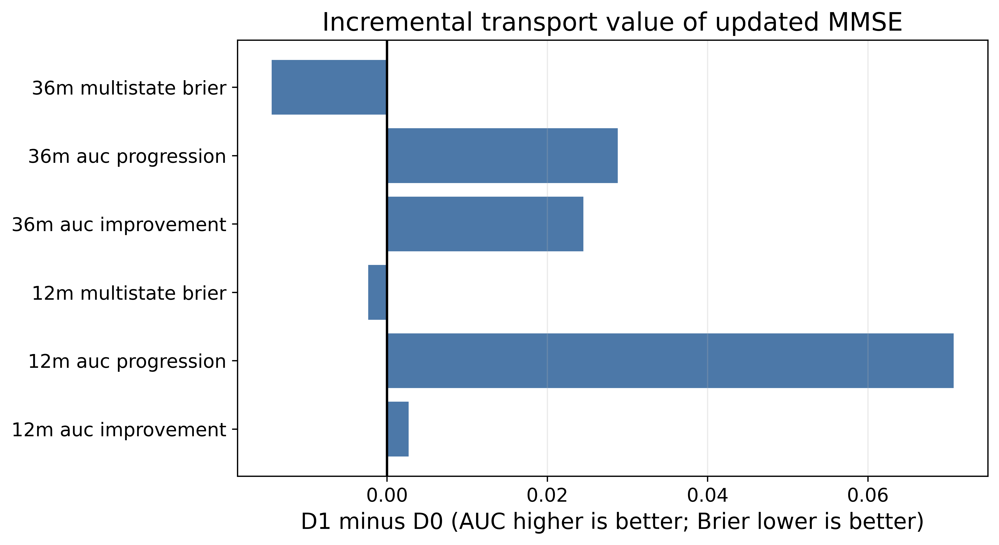

In [12]:
display(Image(filename=str(PLOTS / "d1_vs_d0_transport_value.png"), width=1050))

## 5. Internal-to-external transport and dataset shift

In [13]:
transport = pd.read_csv(TABLES / "adni_oasis_performance_comparison.csv")
selected_transport = transport[
    transport["model_id"].isin(["B1", "D0", "D1"])
    & transport["horizon_months"].isin([12, 36])
    & transport["metric"].isin([
        "auc_improvement", "auc_progression",
        "c_index_improvement", "c_index_progression",
        "multistate_brier", "calibration_slope_improvement",
        "calibration_slope_progression",
        "observed_expected_improvement",
        "observed_expected_progression",
    ])
]
display(selected_transport)
display(pd.read_csv(TABLES / "transportability_classification.csv"))

,model_id,family,horizon_months,metric,adni_internal,oasis_external,oasis_minus_adni
0,B1,baseline,12,auc_improvement,0.673278,0.695569,0.022291
1,B1,baseline,12,auc_progression,0.790096,0.686107,-0.103989
2,B1,baseline,12,c_index_improvement,0.665683,0.677881,0.012198
3,B1,baseline,12,c_index_progression,0.777624,0.678121,-0.099503
6,B1,baseline,12,multistate_brier,0.194854,0.263377,0.068523
7,B1,baseline,12,calibration_slope_improvement,1.168489,1.418170,0.249681
8,B1,baseline,12,calibration_slope_progression,1.096163,0.655787,-0.440376
9,B1,baseline,12,observed_expected_improvement,0.994518,2.179343,1.184826
10,B1,baseline,12,observed_expected_progression,1.008222,0.648185,-0.360037
28,B1,baseline,36,auc_improvement,0.697755,0.719800,0.022045


,selected_model,primary_horizons,minimum_external_auc_across_causes_horizons,median_internal_minus_external_auc,untouched_calibration_within_prespecified_bounds,classification,classification_rule_source
0,D1,12|36,0.68,0.035255,False,TRANSPORTABLE WITH RECALIBRATION,config/phase4_analysis_parameters.json


In [14]:
display(Image(filename=str(PLOTS / "adni_oasis_auc_transport.png"), width=1050))

In [15]:
continuous_shift = pd.read_csv(TABLES / "predictor_distribution_shift.csv")
categorical_shift = pd.read_csv(TABLES / "categorical_distribution_shift.csv")
event_shift = pd.read_csv(TABLES / "event_rate_shift.csv")
display(continuous_shift)
display(categorical_shift)
display(event_shift)

,model_id,family,horizon_months,feature,adni_rows,oasis_rows,adni_missing_percent,oasis_missing_percent,adni_mean,oasis_mean,adni_sd,oasis_sd,adni_median,oasis_median,standardized_mean_difference,absolute_standardized_mean_difference,oasis_outside_adni_range_percent
0,B1,baseline,12,age_at_landmark,2447,491,0.000000,0.000000,73.105040,74.945438,7.906790,7.422851,73.393566,75.060000,0.239990,0.239990,0.407332
1,B1,baseline,12,education_years,2447,491,0.000000,0.407332,15.768288,15.406953,2.872432,2.929505,16.000000,16.000000,-0.124551,0.124551,0.610998
2,B1,baseline,12,apoe_e4_dose,2447,491,27.666530,0.814664,0.597175,0.581109,0.674072,0.635937,0.000000,1.000000,-0.024518,0.024518,0.000000
3,B1,baseline,12,index_mmse,2447,491,0.000000,0.000000,27.088680,27.187373,2.428517,2.537378,28.000000,28.000000,0.039739,0.039739,0.000000
4,B1,baseline,36,age_at_landmark,2447,491,0.000000,0.000000,73.105040,74.945438,7.906790,7.422851,73.393566,75.060000,0.239990,0.239990,0.407332
5,B1,baseline,36,education_years,2447,491,0.000000,0.407332,15.768288,15.406953,2.872432,2.929505,16.000000,16.000000,-0.124551,0.124551,0.610998
6,B1,baseline,36,apoe_e4_dose,2447,491,27.666530,0.814664,0.597175,0.581109,0.674072,0.635937,0.000000,1.000000,-0.024518,0.024518,0.000000
7,B1,baseline,36,index_mmse,2447,491,0.000000,0.000000,27.088680,27.187373,2.428517,2.537378,28.000000,28.000000,0.039739,0.039739,0.000000
8,B3,baseline,12,age_at_landmark,2447,491,0.000000,0.000000,73.105040,74.945438,7.906790,7.422851,73.393566,75.060000,0.239990,0.239990,0.407332
9,B3,baseline,12,education_years,2447,491,0.000000,0.407332,15.768288,15.406953,2.872432,2.929505,16.000000,16.000000,-0.124551,0.124551,0.610998


,model_id,family,horizon_months,feature,level,adni_percent,oasis_percent,oasis_minus_adni_percentage_points
0,B1,baseline,12,sex,Female,45.647732,48.065173,2.417441
1,B1,baseline,12,sex,Male,54.352268,51.934827,-2.417441
2,B1,baseline,36,sex,Female,45.647732,48.065173,2.417441
3,B1,baseline,36,sex,Male,54.352268,51.934827,-2.417441
4,B3,baseline,12,sex,Female,45.647732,48.065173,2.417441
5,B3,baseline,12,sex,Male,54.352268,51.934827,-2.417441
6,B3,baseline,36,sex,Female,45.647732,48.065173,2.417441
7,B3,baseline,36,sex,Male,54.352268,51.934827,-2.417441
8,D0,dynamic,12,sex,Female,39.605933,41.025641,1.419708
9,D0,dynamic,12,sex,Male,60.394067,58.974359,-1.419708


,model_id,family,horizon_months,cause,adni_ipcw_observed_rate,oasis_ipcw_observed_rate,oasis_minus_adni,oasis_to_adni_ratio
0,B1,baseline,12,improvement,0.046960,0.103790,0.056831,2.210197
1,B1,baseline,12,progression,0.064065,0.041516,-0.022549,0.648027
2,B1,baseline,24,improvement,0.132364,0.337045,0.204682,2.546357
3,B1,baseline,24,progression,0.166963,0.137438,-0.029525,0.823165
4,B1,baseline,36,improvement,0.175535,0.407710,0.232174,2.322663
5,B1,baseline,36,progression,0.245763,0.250204,0.004442,1.018073
6,B1,baseline,60,improvement,0.253930,0.459989,0.206059,1.811481
7,B1,baseline,60,progression,0.379287,0.398993,0.019706,1.051955
8,B3,baseline,12,improvement,0.046960,0.103790,0.056831,2.210197
9,B3,baseline,12,progression,0.064065,0.041516,-0.022549,0.648027


In [16]:
display(Image(filename=str(PLOTS / "oasis_adni_distribution_shift_heatmap.png"), width=1000))

## 6. B3, D3, clinical-MCI, and extended-horizon sensitivities

In [17]:
sensitivities = metrics[
    metrics["model_id"].isin(["B3", "D3"])
    & metrics["horizon_months"].isin([12, 36])
]
display(sensitivities[primary_columns].sort_values(["model_id", "horizon_months"]))

extended = metrics[
    metrics["model_id"].isin(["B1", "D1"])
    & metrics["horizon_months"].isin([24, 60])
]
display(extended[primary_columns].sort_values(["model_id", "horizon_months"]))

clinical_mci = pd.read_csv(TABLES / "clinical_mci_subgroup_results.csv")
display(clinical_mci)

,model_id,horizon_months,rows,participants,improvement_events,progression_events,auc_improvement,auc_progression,c_index_improvement,c_index_progression,brier_improvement,brier_progression,multistate_brier,calibration_intercept_improvement,calibration_slope_improvement,observed_expected_improvement,calibration_intercept_progression,calibration_slope_progression,observed_expected_progression
4,B3,12,491,491,45,18,0.690617,0.688425,0.674777,0.680477,0.093826,0.041026,0.263778,0.835023,1.413797,2.169434,-0.462496,0.650243,0.645083
5,B3,36,491,491,170,101,0.694847,0.703405,0.630462,0.648064,0.270058,0.170093,0.727310,1.122356,0.940581,2.227276,0.010334,0.692975,1.007788
12,D3,12,421,207,21,34,0.579334,0.670444,0.573976,0.665428,0.048675,0.074173,0.240092,0.725748,0.522203,2.011932,0.217051,1.146290,1.222334
13,D3,36,421,207,73,164,0.707249,0.698944,0.657321,0.622805,0.153608,0.241101,0.682216,0.649791,1.929832,1.740543,0.533020,0.803942,1.399295


,model_id,horizon_months,rows,participants,improvement_events,progression_events,auc_improvement,auc_progression,c_index_improvement,c_index_progression,brier_improvement,brier_progression,multistate_brier,calibration_intercept_improvement,calibration_slope_improvement,observed_expected_improvement,calibration_intercept_progression,calibration_slope_progression,observed_expected_progression
1,B1,24,491,491,143,58,0.719725,0.714928,0.649494,0.674073,0.244443,0.113411,0.648513,1.166622,1.263355,2.465878,-0.243912,0.688739,0.813304
3,B1,60,491,491,187,150,0.744323,0.745146,0.647198,0.640115,0.251825,0.203942,0.633140,0.920720,1.113245,1.816009,0.027449,0.859332,1.016725
9,D1,24,845,437,197,171,0.739821,0.716824,0.689676,0.669721,0.193890,0.149559,0.622459,1.140250,1.777778,2.613126,0.102225,0.921763,1.084825
11,D1,60,845,437,278,357,0.765146,0.760446,0.687522,0.650773,0.224802,0.206845,0.620475,0.860257,1.453962,1.870862,0.193888,0.866250,1.109392


,model_id,horizon_months,rows,participants,improvement_events,progression_events,auc_improvement,auc_progression,c_index_improvement,c_index_progression,brier_improvement,brier_progression,brier_remaining,multistate_brier,calibration_intercept_improvement,calibration_slope_improvement,observed_expected_improvement,observed_rate_improvement,expected_rate_improvement,calibration_intercept_progression,calibration_slope_progression,observed_expected_progression,observed_rate_progression,expected_rate_progression,known_rows,ipcw_effective_n
0,B1,12,92,92,18,1,0.615475,0.388129,0.587302,0.415385,0.192323,0.014898,0.194488,0.401709,1.539823,0.712235,3.869788,0.216710,0.056001,-1.221886,-0.947830,0.303310,0.012245,0.040371,81,80.981733
1,B1,36,92,92,53,3,0.576194,0.631331,0.537692,0.589744,0.420144,0.062959,0.316280,0.799383,1.972631,0.518396,3.050235,0.668760,0.219249,-1.628766,0.864786,0.228312,0.039984,0.175127,76,75.558154
2,D1,12,133,84,21,4,0.677183,0.579863,0.648312,0.553241,0.148261,0.029604,0.164916,0.342781,1.520257,1.938289,3.996337,0.161488,0.040409,-0.675119,1.157902,0.524458,0.031294,0.059669,127,126.981309
3,D1,36,133,84,61,20,0.707092,0.722153,0.649469,0.638501,0.342250,0.124440,0.301687,0.768377,1.638943,1.579247,3.112549,0.490918,0.157722,-0.387464,1.204830,0.733734,0.171089,0.233176,116,114.979440


## 7. Reconstructed six-box global CDR sensitivity

The same frozen predictions are evaluated against the reconstructed endpoint;
no model was refit.

In [18]:
endpoint_counts = pd.read_csv(TABLES / "reconstructed_cdr_eligibility_event_counts.csv")
endpoint_delta = pd.read_csv(TABLES / "reconstructed_cdr_metric_comparison.csv")
display(endpoint_counts)
display(endpoint_delta[
    endpoint_delta["model_id"].isin(["B1", "D0", "D1"])
    & endpoint_delta["horizon_months"].isin([12, 36])
    & endpoint_delta["metric"].isin([
        "auc_improvement", "auc_progression",
        "c_index_improvement", "c_index_progression",
        "multistate_brier",
    ])
])

,model_id,family,horizon_months,primary_rows,reconstructed_eligible_rows,eligibility_change_rows,primary_participants,reconstructed_participants,primary_improvement_events,reconstructed_improvement_events,primary_progression_events,reconstructed_progression_events
0,B1,baseline,12,491,491,0,491,491,45,45,18,17
1,B1,baseline,24,491,491,0,491,491,143,146,58,57
2,B1,baseline,36,491,491,0,491,491,170,173,101,99
3,B1,baseline,60,491,491,0,491,491,187,191,150,147
4,B3,baseline,12,491,491,0,491,491,45,45,18,17
5,B3,baseline,36,491,491,0,491,491,170,173,101,99
6,D0,dynamic,12,858,854,-4,437,437,66,67,52,48
7,D0,dynamic,36,858,854,-4,437,437,243,248,265,255
8,D1,dynamic,12,845,841,-4,437,437,66,67,49,45
9,D1,dynamic,24,845,841,-4,437,437,197,203,171,165


,model_id,family,horizon_months,metric,cdrtot_primary,reconstructed_cdr,reconstructed_minus_cdrtot
0,B1,baseline,12,auc_improvement,0.695569,0.695573,0.000004
1,B1,baseline,12,auc_progression,0.686107,0.666991,-0.019116
2,B1,baseline,12,c_index_improvement,0.677881,0.678184,0.000303
3,B1,baseline,12,c_index_progression,0.678121,0.659690,-0.018431
6,B1,baseline,12,multistate_brier,0.263377,0.262194,-0.001183
28,B1,baseline,36,auc_improvement,0.719800,0.711924,-0.007877
29,B1,baseline,36,auc_progression,0.719233,0.714165,-0.005068
30,B1,baseline,36,c_index_improvement,0.646754,0.642072,-0.004682
31,B1,baseline,36,c_index_progression,0.647635,0.639727,-0.007908
34,B1,baseline,36,multistate_brier,0.730509,0.735900,0.005391


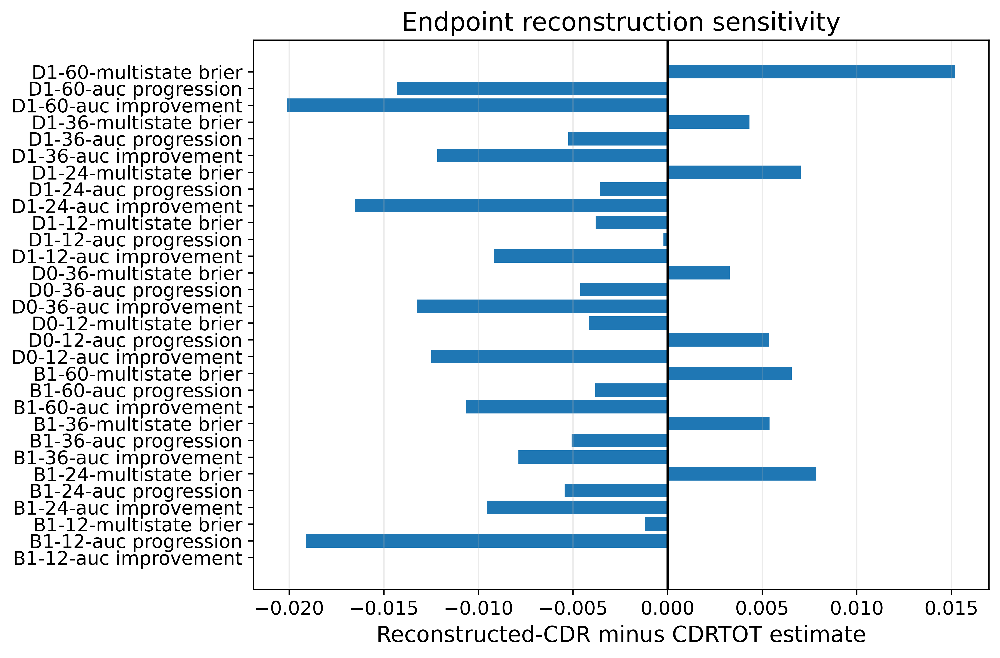

In [19]:
display(Image(filename=str(PLOTS / "reconstructed_cdr_sensitivity.png"), width=1050))

## 8. Participant-grouped cross-fitted recalibration

These are model-updating results, not untouched external validation. The
recalibration refits only calibration intercepts/slopes and never predictor
coefficients.

In [20]:
recal_params = pd.read_csv(TABLES / "cross_fitted_recalibration_parameters.csv")
recal_metrics = pd.read_csv(TABLES / "cross_fitted_recalibration_metrics.csv")
recal_effect = pd.read_csv(TABLES / "recalibration_effect_comparison.csv")

display(recal_params.groupby(
    ["model_id", "horizon_months", "method", "cause"], as_index=False
).agg(
    folds=("fold", "nunique"),
    total_training_events=("training_events", "sum"),
    predictors_refit=("predictor_coefficients_refit", "max"),
))
display(recal_metrics)
display(recal_effect[[
    "model_id", "horizon_months", "method",
    "multistate_brier", "calibration_slope_improvement",
    "observed_expected_improvement", "calibration_slope_progression",
    "observed_expected_progression",
]])

,model_id,horizon_months,method,cause,folds,total_training_events,predictors_refit
0,B1,12,calibration_in_the_large,improvement,5,180,False
1,B1,12,calibration_in_the_large,progression,5,72,False
2,B1,12,intercept_and_slope,improvement,5,180,False
3,B1,12,intercept_and_slope,progression,5,72,False
4,B1,36,calibration_in_the_large,improvement,5,680,False
5,B1,36,calibration_in_the_large,progression,5,404,False
6,B1,36,intercept_and_slope,improvement,5,680,False
7,B1,36,intercept_and_slope,progression,5,404,False
8,D0,12,calibration_in_the_large,improvement,5,264,False
9,D0,12,calibration_in_the_large,progression,5,208,False


,model_id,horizon_months,method,validation_design,rows,participants,auc_improvement,auc_progression,c_index_improvement,c_index_progression,brier_improvement,brier_progression,brier_remaining,multistate_brier,calibration_intercept_improvement,calibration_slope_improvement,observed_expected_improvement,observed_rate_improvement,expected_rate_improvement,calibration_intercept_progression,calibration_slope_progression,observed_expected_progression,observed_rate_progression,expected_rate_progression,known_rows,ipcw_effective_n
0,B1,12,calibration_in_the_large,5-fold participant-grouped cross-fitting,491,491,0.677160,0.661296,0.660201,0.653180,0.089877,0.039752,0.124719,0.254347,0.058187,1.295331,1.053695,0.103790,0.098501,-0.016477,0.558573,0.984337,0.041516,0.042176,431,430.996652
1,B1,12,intercept_and_slope,5-fold participant-grouped cross-fitting,491,491,0.681084,0.629812,0.663748,0.623389,0.089693,0.039569,0.123963,0.253226,0.081791,0.942984,1.076383,0.103790,0.096425,-0.047826,0.653729,0.955239,0.041516,0.043461,431,430.996652
2,B1,36,calibration_in_the_large,5-fold participant-grouped cross-fitting,491,491,0.718789,0.711103,0.647085,0.640298,0.218657,0.174133,0.245262,0.638052,0.361860,1.329379,1.258238,0.407710,0.324032,0.198591,0.639214,1.164717,0.250204,0.214820,396,393.947907
3,B1,36,intercept_and_slope,5-fold participant-grouped cross-fitting,491,491,0.713032,0.710469,0.643153,0.639908,0.221641,0.171736,0.242043,0.635420,0.383957,1.265928,1.277240,0.407710,0.319211,0.156488,0.742141,1.127013,0.250204,0.222007,396,393.947907
4,D0,12,calibration_in_the_large,5-fold participant-grouped cross-fitting,858,437,0.676608,0.651556,0.662159,0.645701,0.070029,0.056596,0.120810,0.247435,0.040793,1.028270,1.038385,0.078089,0.075203,0.010312,0.824216,1.009727,0.061604,0.061010,838,837.985610
5,D0,12,intercept_and_slope,5-fold participant-grouped cross-fitting,858,437,0.672568,0.638350,0.658272,0.632406,0.070208,0.056792,0.121001,0.248000,0.040276,0.969509,1.037889,0.078089,0.075239,-0.001964,0.867053,0.998159,0.061604,0.061717,838,837.985610
6,D0,36,calibration_in_the_large,5-fold participant-grouped cross-fitting,858,437,0.711675,0.697227,0.658036,0.627735,0.195041,0.209063,0.249942,0.654046,0.276631,1.743831,1.222087,0.303103,0.248021,0.245572,0.754668,1.184237,0.338116,0.285514,757,752.216285
7,D0,36,intercept_and_slope,5-fold participant-grouped cross-fitting,858,437,0.710413,0.694428,0.657799,0.625771,0.193424,0.208829,0.246476,0.648729,0.319428,1.154601,1.262270,0.303103,0.240125,0.193814,0.760417,1.141557,0.338116,0.296189,757,752.216285
8,D1,12,calibration_in_the_large,5-fold participant-grouped cross-fitting,845,437,0.667970,0.712288,0.656599,0.701748,0.071304,0.052513,0.118287,0.242104,0.034734,1.617489,1.032555,0.078923,0.076434,0.009687,0.989947,1.009163,0.058660,0.058127,832,831.994957
9,D1,12,intercept_and_slope,5-fold participant-grouped cross-fitting,845,437,0.670485,0.712318,0.658791,0.701827,0.071101,0.052702,0.118660,0.242464,0.050340,0.942118,1.047554,0.078923,0.075340,-0.004832,0.896377,0.995462,0.058660,0.058927,832,831.994957


,model_id,horizon_months,method,multistate_brier,calibration_slope_improvement,observed_expected_improvement,calibration_slope_progression,observed_expected_progression
0,B1,12,untouched,0.263377,1.418170,2.179343,0.655787,0.648185
1,B1,36,untouched,0.730509,1.067938,2.244852,0.671430,1.016128
2,D0,12,untouched,0.251117,0.991375,2.076150,0.851765,0.802234
3,D0,36,untouched,0.720751,1.617411,2.291737,0.747241,1.129711
4,D1,12,untouched,0.245419,1.697333,2.153523,1.085480,0.796474
5,D1,36,untouched,0.707110,1.643548,2.282595,0.832601,1.142928
6,B1,12,calibration_in_the_large,0.254347,1.295331,1.053695,0.558573,0.984337
7,B1,12,intercept_and_slope,0.253226,0.942984,1.076383,0.653729,0.955239
8,B1,36,calibration_in_the_large,0.638052,1.329379,1.258238,0.639214,1.164717
9,B1,36,intercept_and_slope,0.635420,1.265928,1.277240,0.742141,1.127013


In [21]:
display(Image(filename=str(PLOTS / "cross_fitted_recalibration_effect.png"), width=1050))

## 9. Final decision and saved deliverables

In [22]:
metadata = json.loads((TABLES / "phase4_run_metadata.json").read_text())
outputs = pd.read_csv(TABLES / "phase4_required_output_status.csv")
figure_qc = pd.read_csv(TABLES / "phase4_figure_verification.csv")

display(outputs)
display(figure_qc)
print("Transportability:", metadata["transportability_classification"])
print("Independent QC pass:", metadata["independent_final_qc_pass"])
print("Phase 4 complete:", metadata["phase4_complete"])
print("Phase 5 started:", metadata["phase5_started"])
print("\nFINAL DECISION:", metadata["decision"])

,required_output,path,status,bytes
0,repaired-lock checksum verification,results/csvs/phase4/lock_checksum_verification...,COMPLETE,11771
1,frozen model inventory,results/csvs/phase4/frozen_package_completenes...,COMPLETE,1901
2,outcome-hidden feature manifest,results/csvs/phase4/outcome_hidden_feature_man...,COMPLETE,8383
3,outcome-hidden prediction manifest,results/csvs/phase4/outcome_hidden_prediction_...,COMPLETE,13620
4,independent prediction QC,results/csvs/phase4/phase4_independent_predict...,COMPLETE,435
5,access audit,results/csvs/phase4/phase4_access_audit.csv,COMPLETE,6897
6,untouched metrics,results/csvs/phase4/untouched_external_metrics...,COMPLETE,8076
7,untouched integrated Brier scores,results/csvs/phase4/untouched_integrated_brier...,COMPLETE,1801
8,participant bootstrap estimates,results/csvs/phase4/participant_bootstrap_metr...,COMPLETE,1956744
9,participant bootstrap confidence intervals,results/csvs/phase4/participant_bootstrap_conf...,COMPLETE,10952


,figure,svg,width_pixels,height_pixels,observed_dpi_x,observed_dpi_y,required_dpi,status
0,results/plots/phase4/phase4_stage_gate_workflo...,results/plots/phase4/phase4_stage_gate_workflo...,17880,5280,1199.9976,1199.9976,1200,PASS
1,results/plots/phase4/untouched_oasis_calibrati...,results/plots/phase4/untouched_oasis_calibrati...,9432,10567,1199.9976,1199.9976,1200,PASS
2,results/plots/phase4/adni_oasis_auc_transport.png,results/plots/phase4/adni_oasis_auc_transport.svg,10483,6971,1199.9976,1199.9976,1200,PASS
3,results/plots/phase4/oasis_adni_distribution_s...,results/plots/phase4/oasis_adni_distribution_s...,8605,6427,1199.9976,1199.9976,1200,PASS
4,results/plots/phase4/cross_fitted_recalibratio...,results/plots/phase4/cross_fitted_recalibratio...,13363,6961,1199.9976,1199.9976,1200,PASS
5,results/plots/phase4/d1_vs_d0_transport_value.png,results/plots/phase4/d1_vs_d0_transport_value.svg,5288,2882,599.9988,599.9988,600,PASS
6,results/plots/phase4/reconstructed_cdr_sensiti...,results/plots/phase4/reconstructed_cdr_sensiti...,5289,3482,599.9988,599.9988,600,PASS


Transportability: TRANSPORTABLE WITH RECALIBRATION
Independent QC pass: True
Phase 4 complete: True
Phase 5 started: False

FINAL DECISION: GO TO PHASE 5 WITH RESTRICTIONS


In [23]:
report_paths = sorted(REPORTS.glob("phase4_*.md"))
for path in report_paths:
    print(f"{path.name}: {path.stat().st_size:,} bytes")

display(Markdown((REPORTS / "phase4_phase5_handoff.md").read_text()))

phase4_d1_vs_d0_transportability_report.md: 7,372 bytes
phase4_distribution_shift_report.md: 9,757 bytes
phase4_endpoint_sensitivity_report.md: 9,645 bytes
phase4_frozen_package_blocker_audit.md: 350 bytes
phase4_independent_qc_report.md: 11,291 bytes
phase4_locked_external_validation_report.md: 49,565 bytes
phase4_phase5_handoff.md: 812 bytes
phase4_prediction_independent_qc_report.md: 6,834 bytes
phase4_recalibration_report.md: 7,849 bytes
phase4_stage_a_lock_and_prediction_report.md: 9,762 bytes
phase4_untouched_calibration_report.md: 3,014 bytes
phase4_updated_model_card.md: 790 bytes


# Phase 4 to Phase 5 Handoff

Generated: 2026-07-29T14:24:19.026757+00:00

## Decision

**GO TO PHASE 5 WITH RESTRICTIONS**

Independent final QC: **PASS**
(28/28 critical checks passing).

Phase 4 transportability classification:
**TRANSPORTABLE WITH RECALIBRATION**.

Phase 5 may use the completed Phase 4 outputs only with these restrictions:

1. retain provisional OASIS `CDRTOT` endpoint language;
2. explicitly flag low precision for 12-month B1 progression (18 events);
3. treat untouched external results as primary and recalibration as model updating;
4. preserve participant-grouped handling for repeated landmarks;
5. do not retrospectively select or alter Phase 3 models using OASIS results;
6. carry reconstructed six-box CDR results as endpoint sensitivity.

Phase 5 was not started automatically.


### Interpretation

The frozen ADNI models retain useful discrimination in OASIS-3, with D1
showing added progression discrimination over D0 on identical landmarks.
Untouched calibration is not consistently transportable, especially for the
improvement transition, so cross-fitted recalibration is retained as explicit
model updating. Endpoint reconstruction does not materially reverse the main
conclusions.

**Final decision: `GO TO PHASE 5 WITH RESTRICTIONS`.**

Phase 5 has not been started.